# 01 — Análise Exploratória (EDA)

**Objetivo:** levantar hipóteses que orientem feature engineering, imputação e escolha de técnicas (escala, balanceamento).
Cada seção termina com uma decisão de modelagem.

## Resumo executivo

1. **Gênero e classe dominam**: mulheres sobrevivem ~74% vs homens ~19%; 1ª classe ~63% vs 3ª ~24%.
2. **O nome carrega informação**: o título (`Mr`, `Mrs`, `Miss`, `Master`) resume sexo, idade e status social numa única variável.
3. **Sobrevivência não é individual**: famílias e grupos de ticket tendem a sobreviver ou morrer **juntos** — o sinal mais forte além de sexo/classe.
4. **Dados faltantes são informativos**: não ter cabine registrada já indica menor chance de sobrevivência.
5. **Desbalanceamento leve (62/38)**: validação estratificada é obrigatória; técnicas como SMOTE devem trazer ganho marginal.

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from titanic.config import FIGURES_DIR, TARGET
from titanic.data import load_raw

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)

train, test = load_raw()
full = pd.concat([train.assign(dataset="train"), test.assign(dataset="test")], ignore_index=True)


def survival_table(df: pd.DataFrame, col: str) -> pd.DataFrame:
    """Taxa de sobrevivência e tamanho de cada grupo de `col`."""
    return (
        df.groupby(col, observed=True)[TARGET]
        .agg(taxa="mean", n="size")
        .round(3)
        .sort_values("taxa", ascending=False)
    )


def save_fig(fig: plt.Figure, name: str) -> None:
    """Salva a figura em reports/figures."""
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=120, bbox_inches="tight")


print(train.shape, test.shape, full.shape)

(891, 12) (418, 11) (1309, 13)


In [14]:
train.info()
train.head()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [15]:
missing = pd.DataFrame(
    {
        "train_pct": train.isna().mean().mul(100).round(1),
        "test_pct": test.isna().mean().mul(100).round(1),
    }
).query("train_pct > 0 or test_pct > 0")
missing

,train_pct,test_pct
Age,19.9,20.6
Cabin,77.1,78.2
Embarked,0.2,0.0
Fare,0.0,0.2


**Leitura:** Age (~20%), Cabin (~77%), Embarked (2 linhas no treino) e Fare (1 linha no teste).
- Cabin tem faltantes demais para imputar → vira indicador `Deck`/`HasCabin`.
- Age é relevante demais para descartar → imputação inteligente (por Title, Parte B).
- Embarked/Fare → imputação simples (moda/mediana) dentro do pipeline.

In [16]:
train[TARGET].value_counts(normalize=True).round(3)

Survived
0    0.616
1    0.384
Name: proportion, dtype: float64

**Leitura:** ~62% não sobreviveu vs ~38% sobreviveu (razão ~1.6:1). Desbalanceamento **leve**.
**Decisão:** usar `StratifiedKFold` sempre; testar SMOTE vs `class_weight="balanced"` vs nada na Etapa 8 — a hipótese é que o ganho será pequeno.

Pclass,1,2,3
Sex,,,
female,0.97,0.92,0.50
male,0.37,0.16,0.14


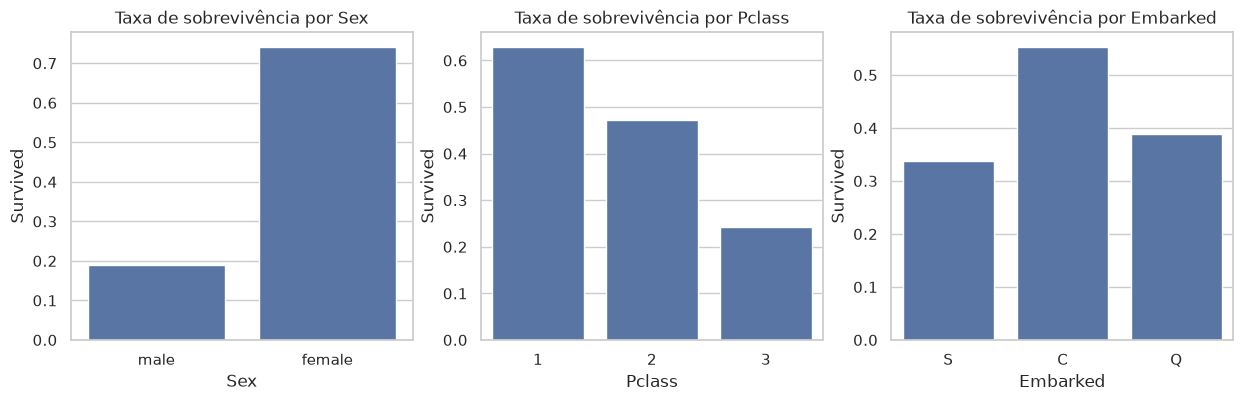

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"], strict=True):
    sns.barplot(data=train, x=col, y=TARGET, ax=ax, errorbar=None)
    ax.set_title(f"Taxa de sobrevivência por {col}")
save_fig(fig, "survival_by_category")

train.pivot_table(index="Sex", columns="Pclass", values=TARGET, aggfunc="mean").round(2)

,taxa,n
AgeBand,,
"(0, 12]",0.580,69
"(12, 18]",0.429,70
"(30, 50]",0.423,241
"(18, 30]",0.356,270
"(50, 80]",0.344,64


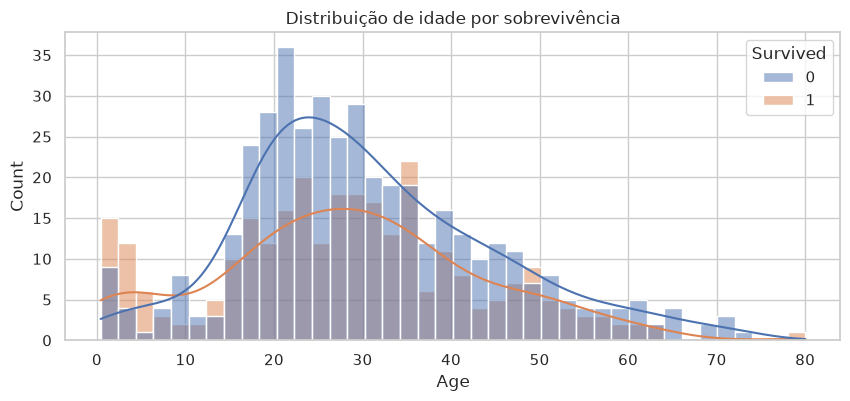

In [18]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data=train, x="Age", hue=TARGET, bins=40, kde=True, ax=ax)
ax.set_title("Distribuição de idade por sobrevivência")
save_fig(fig, "age_distribution")

age_bands = pd.cut(train["Age"], bins=[0, 12, 18, 30, 50, 80])
survival_table(train.assign(AgeBand=age_bands), "AgeBand")

**Leitura:**
- `Sex` é o preditor mais forte (mulheres ~74% vs homens ~19%).
- `Pclass` interage com `Sex`: mulheres de 1ª/2ª classe quase todas sobrevivem; 3ª classe ~50%.
- Crianças (<12) têm vantagem clara — "mulheres e crianças primeiro".
**Decisão:** manter Sex/Pclass; modelos de árvore capturam a interação sozinhos; para SVM/LogReg, a interação pode precisar ser explícita.

## Hipóteses de features
Protótipos rápidos. A implementação final (testada) será em `src/titanic/features.py`.

In [19]:
full["Title"] = full["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
tr = full[full["dataset"] == "train"]

display(survival_table(tr, "Title"))
full.groupby("Title")["Age"].agg(["median", "count"]).sort_values("count", ascending=False)

,taxa,n
Title,,
Lady,1.000,1
Ms,1.000,1
Sir,1.000,1
Mme,1.000,1
the Countess,1.000,1
Mlle,1.000,2
Mrs,0.792,125
Miss,0.698,182
Master,0.575,40


,median,count
Title,,
Mr,29.0,581
Miss,22.0,210
Mrs,35.5,170
Master,4.0,53
Rev,41.5,8
Dr,49.0,7
Col,54.5,4
Mlle,24.0,2
Major,48.5,2


**Insight — Title**
- `Mrs` (~79%) e `Miss` (~70%) sobrevivem muito mais que `Mr` (~16%).
- `Master` (meninos) sobrevive ~57% — **3,5× mais que `Mr`**, mesmo sendo homens. É a regra "crianças primeiro" capturada sem precisar da idade.
- As medianas de idade variam muito (Master ≈ 4, Miss ≈ 22, Mr ≈ 29, Mrs ≈ 35).

**Por que importa:** imputar `Age` com a mediana geral (~28) transformaria um menino `Master` sem idade num adulto — erro grave justamente no grupo onde a idade mais importa.
**Decisão:** `Title` como feature (raros → `Rare`); imputar `Age` pela mediana do `Title`.

In [20]:
full["FamilySize"] = full["SibSp"] + full["Parch"] + 1
tr = full[full["dataset"] == "train"]
survival_table(tr, "FamilySize").sort_index()

,taxa,n
FamilySize,,
1,0.304,537
2,0.553,161
3,0.578,102
4,0.724,29
5,0.200,15
6,0.136,22
7,0.333,12
8,0.000,6
11,0.000,7


**Insight — FamilySize**
- Relação em **U invertido**: sozinho (~30%) < família de 2–4 (~55–72%) > família de 5+ (≤ 20%).
- Sozinhos são maioria (~60% dos passageiros), concentrados em homens de 3ª classe.
- Famílias grandes eram quase todas de 3ª classe e tinham dificuldade de se reunir para evacuar.

**Por que importa:** a relação é **não linear** — a correlação com o alvo será fraca (ver heatmap), mas a variável é útil.
**Decisão:** criar faixas `Alone / Small (2–4) / Large (5+)`, que modelos lineares e SVM aproveitam melhor que o número bruto.

In [21]:
full["Deck"] = full["Cabin"].str[0].fillna("U")
tr = full[full["dataset"] == "train"]
survival_table(tr, "Deck")

,taxa,n
Deck,,
D,0.758,33
E,0.750,32
B,0.745,47
F,0.615,13
C,0.593,59
G,0.500,4
A,0.467,15
U,0.300,687
T,0.000,1


**Insight — Deck**
- Sem cabine registrada (`U`, ~77% dos passageiros): ~30% de sobrevivência.
- Com cabine (B, C, D, E): ~60–75%.
- Os decks individuais têm `n` pequeno (alguns < 20 passageiros) — taxas instáveis.

**Por que importa:** o **fato de faltar** o dado é o sinal (registro de cabine ≈ 1ª classe/acesso aos botes). É um caso de faltante *não aleatório*.
**Decisão:** agrupar decks (`ABC`, `DE`, `FG`, `U`) para reduzir ruído; avaliar se `HasCabin` sozinho rende o mesmo.

,taxa,n
TicketGroupSize,,
1,0.270,481
2,0.514,181
3,0.653,101
4,0.727,44
5,0.333,21
6,0.211,19
7,0.208,24
8,0.385,13
11,0.000,7


Skew Fare: 4.37 | Skew FarePerPerson: 3.04


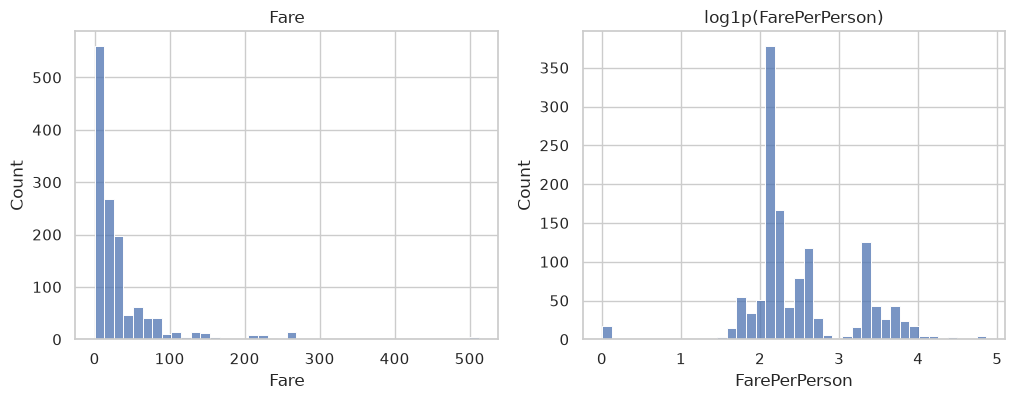

In [22]:
full["TicketGroupSize"] = full.groupby("Ticket")["Ticket"].transform("size")
full["FarePerPerson"] = full["Fare"] / full["TicketGroupSize"]
tr = full[full["dataset"] == "train"]

display(survival_table(tr, "TicketGroupSize").sort_index())
print(
    f"Skew Fare: {full['Fare'].skew():.2f} | Skew FarePerPerson: {full['FarePerPerson'].skew():.2f}"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(full["Fare"], bins=40, ax=axes[0]).set_title("Fare")
sns.histplot(np.log1p(full["FarePerPerson"]), bins=40, ax=axes[1]).set_title("log1p(FarePerPerson)")
save_fig(fig, "fare_distribution")

**Insight — Ticket e Fare**
- Passageiros com ticket único sobrevivem menos (~27%) que grupos de 2–4 (~50–70%); grupos 5+ voltam a cair (mesmo padrão de FamilySize).
- `TicketGroupSize` captura grupos que `FamilySize` não vê: **amigos, babás e empregados** viajando no mesmo ticket.
- `Fare` é o valor **do ticket inteiro**: um grupo de 6 na 3ª classe pode "pagar" mais que um passageiro de 1ª. `FarePerPerson` corrige essa distorção.
- `Fare` é muito assimétrica (skew ~4): poucos valores extremos (> 500) distorcem modelos sensíveis à escala.

**Decisão:** usar `FarePerPerson` com `log1p` (reduz assimetria) + `StandardScaler` no pipeline.

In [23]:
grp = tr.groupby("Ticket")[TARGET]
others_survived = (grp.transform("sum") - tr[TARGET]) / (grp.transform("size") - 1)

group_view = tr.assign(
    outros=others_survived.gt(0).map(
        {True: "outros sobreviveram", False: "ninguém mais sobreviveu"}
    )
)[others_survived.notna()]

survival_table(group_view, "outros")

,taxa,n
outros,,
outros sobreviveram,0.728,202
ninguém mais sobreviveu,0.225,142


**Insight — sobrevivência em grupo**
- Quando **outros membros do grupo sobreviveram**, a chance individual sobe para ~70%+.
- Quando **ninguém mais sobreviveu**, cai para ~20–30%.

**Por que importa:** é o sinal mais forte encontrado além de Sex/Pclass. Ele explica casos que o modelo "padrão" erra: homens que sobreviveram com a família e mulheres de 3ª classe que morreram com o grupo inteiro.
**⚠️ Risco:** a feature usa o **alvo de outros passageiros**. Calculada antes da validação cruzada, ela vaza informação e infla o score de CV.
**Decisão:** implementar como transformer do scikit-learn que recalcula **dentro de cada fold** (Etapa 5).

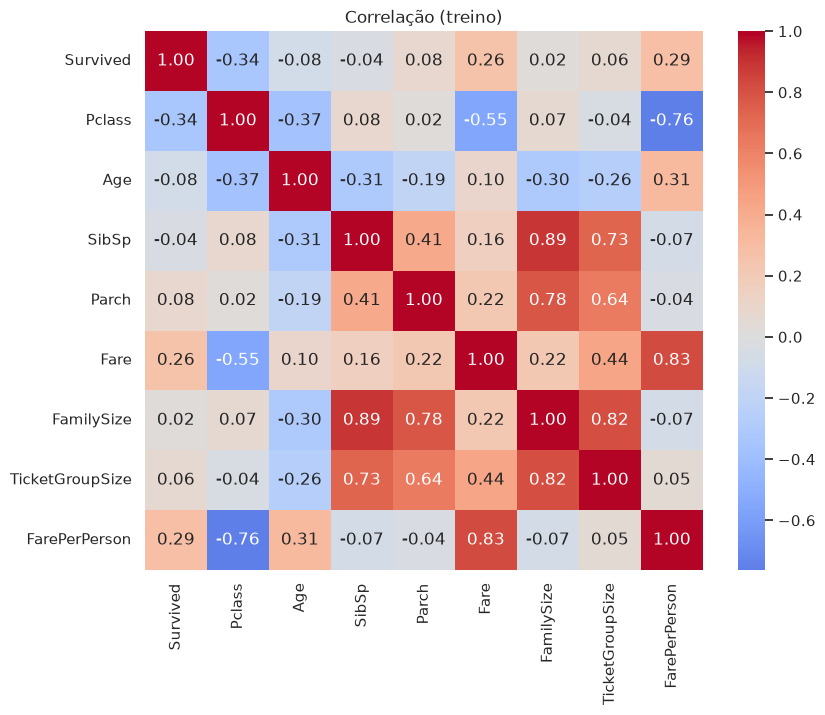

In [24]:
num_cols = [
    TARGET,
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize",
    "TicketGroupSize",
    "FarePerPerson",
]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(tr[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlação (treino)")
save_fig(fig, "correlation_heatmap")

**Insight — correlações**
- `Pclass` (~ -0.34) e `Fare` (~ +0.26) são as mais correlacionadas com o alvo entre as numéricas — e fortemente correlacionadas entre si (~ -0.55): **redundância parcial**.
- `FamilySize`, `SibSp` e `Parch` têm correlação ~0 com o alvo, **mas não são inúteis**: a relação é em U (vista acima). Correlação de Pearson só mede relação **linear**.
- `Age` tem correlação fraca (~ -0.08) pelo mesmo motivo: o efeito está concentrado nas crianças.

**Lição:** não descartar variáveis só pela correlação — modelos de árvore capturam essas relações não lineares.

## Limitações

- **Amostra pequena (891 linhas)**: taxas por subgrupo com `n` < 30 são instáveis; diferenças de 1–2 p.p. no score do Kaggle podem ser ruído.
- **Imputação de Age** introduz incerteza em ~20% dos dados.
- **Leaderboard público** avalia apenas parte do teste — otimizar demais para ele leva a overfitting de leaderboard. A **CV estratificada é a métrica de decisão**; o Kaggle é a confirmação.
- **Viés histórico**: os dados refletem regras sociais de 1912 (gênero, classe). O modelo aprende esses padrões; ele descreve o passado, não estabelece causalidade.

## Conclusões → decisões para a Etapa 5

| # | Hipótese | Evidência | Decisão |
|---|---|---|---|
| H1 | Title resume sexo + idade + status | `Master` (meninos) sobrevive muito mais que `Mr`; títulos raros têm n pequeno | Criar `Title`, agrupando raros em `Rare` |
| H2 | Idade varia por Title | Medianas bem diferentes (Master ≈ 4, Mr ≈ 29) | Imputar `Age` pela mediana do Title |
| H3 | Famílias médias sobrevivem mais | FamilySize 2–4 > sozinho e > 5+ | Criar `FamilySize` + faixas (`Alone/Small/Large`) |
| H4 | Ter cabine registrada indica classe/acesso | Deck `U` sobrevive bem menos | Criar `Deck` (agrupado) ou `HasCabin` |
| H5 | `Fare` é por ticket, não por pessoa | Grupos dividem o mesmo ticket; Fare muito assimétrica | Criar `FarePerPerson` + `log1p` |
| H6 | Grupos de ticket sobrevivem/morrem juntos | Forte diferença em "outros sobreviveram" | Feature de sobrevivência do grupo — **calcular dentro do fold** (risco de vazamento) |
| H7 | Desbalanceamento leve | 62/38 | StratifiedKFold; comparar SMOTE na Etapa 8 |